In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split

In [11]:
DATA_PATH = './dataset/'
x, y = [], []
counter = 0
img_row, img_col = 102, 132
classes = os.listdir(DATA_PATH)
print(classes)

['Boot', 'Sandal', 'Shoe']


In [12]:
for class_path in classes:
    for img_path in os.listdir(f"{DATA_PATH}{class_path}"):
        path = f"{DATA_PATH}{class_path}/{img_path}"
        label = counter
        img = tf.keras.preprocessing.image.load_img(path, target_size=(img_row, img_col))
        img = tf.keras.preprocessing.image.img_to_array(img)
        x.append(img)
        y.append(label)
    counter += 1

x = np.array(x)
y = np.array(y)
x = x.astype('float32') / 255.0

In [17]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=420
)

x_test, x_val, y_test, y_val = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=420
)

y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
y_val = keras.utils.to_categorical(y_val)
print(x_train.shape)

(1200, 102, 132, 3)


In [20]:
import keras.layers

model = keras.Sequential()

model.add(keras.layers.Conv2D(6, (6,6), activation="relu", input_shape=(img_row, img_col, 3)))
model.add(keras.layers.AveragePooling2D((2,2), 2))
model.add(keras.layers.Conv2D(16, (6,6), activation="relu"))
model.add(keras.layers.AveragePooling2D((2,2), 2))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(120, activation="relu"))
model.add(keras.layers.Dense(84, activation="relu"))
model.add(keras.layers.Dense(3, activation="softmax"))

model.summary()


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 97, 127, 6)     │           654 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 48, 63, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 43, 58, 16)     │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 21, 29, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9744)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     1,169,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,183,945 (4.52 MB)

 Trainable params: 1,183,945 (4.52 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['Accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10, batch_size=120, validation_data=(x_val, y_val)
)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 217ms/step - Accuracy: 0.4917 - loss: 1.0513 - val_Accuracy: 0.7867 - val_loss: 0.7730
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - Accuracy: 0.8150 - loss: 0.5444 - val_Accuracy: 0.9000 - val_loss: 0.3230
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step - Accuracy: 0.8825 - loss: 0.3173 - val_Accuracy: 0.9200 - val_loss: 0.2547
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - Accuracy: 0.9350 - loss: 0.2153 - val_Accuracy: 0.9333 - val_loss: 0.2063
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - Accuracy: 0.9417 - loss: 0.1624 - val_Accuracy: 0.8933 - val_loss: 0.3182
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - Accuracy: 0.9542 - loss: 0.1408 - val_Accuracy: 0.9400 - val_loss: 0.1719
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - Accuracy: 0.9700 - loss: 0.0988 - val_Accuracy: 0.9533 - val_loss: 0.1369
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - Accuracy: 0.9742 - loss: 0.0792 - val_Accuracy: 0.

In [23]:
model.evaluate(x_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - Accuracy: 0.9267 - loss: 0.1879


[0.18790310621261597, 0.9266666769981384]

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


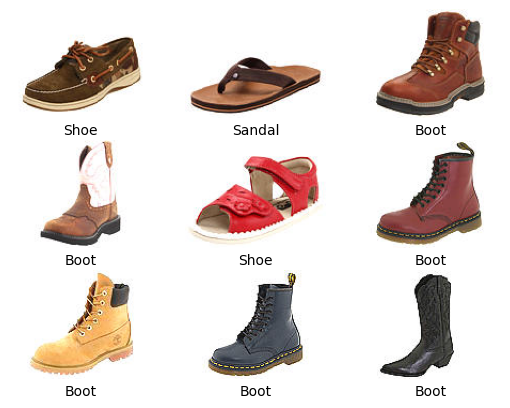

In [25]:
prediction = model.predict(x_test)
predicted_label = np.argmax(prediction, 1)

for i in range(9):
    plt.subplot(3,3, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')
    plt.text(
        0.5, -0.15, 
        classes[predicted_label[i]], fontsize=10, ha='center',
        transform = plt.gca().transAxes
    )

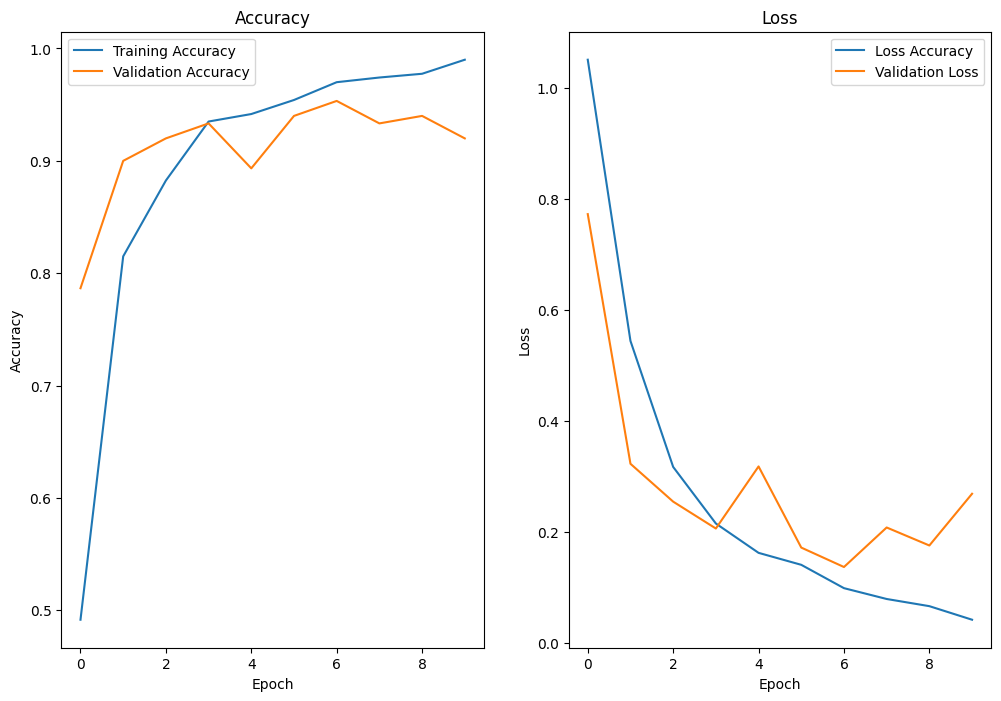

In [28]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 2, 1)
plt.plot(history.history['Accuracy'], label="Training Accuracy")
plt.plot(history.history['val_Accuracy'], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label="Loss Accuracy")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()